# Machine Learning Lab 3
## Decision Tree Classification, Training, Evaluation & Overfitting

**Name:** Muhammad Taraz  
**Student ID:** 023-24-0259  
**Section:** H  
**GitHub Profile:** https://github.com/Muhammad-taraz  
**Kaggle Profile:** https://www.kaggle.com/muhammadtaraz  
**Dataset:** Telco Customer Churn  
**Dataset Source:** Kaggle

## 1. Problem Definition

This lab uses the cleaned Telco Customer Churn dataset from Lab 2. The goal is to build a Decision Tree classifier that predicts whether a customer will churn or stay with the company.

## Part 1, Problem Definition & Dataset Verification
### Task 1

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("clean_churn.csv")

print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nTarget distribution:")
print(df["Churn"].value_counts())

Shape: (7043, 20)

Data types:
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

Missing values:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
Mont

### Task 2

The problem is to predict whether a customer will leave the company or not. This can help the company identify customers who may churn and take action to retain them.

## Part 2, Feature & Target Preparation
### Task 3

In [5]:
y = df["Churn"].map({"No": 0, "Yes": 1})

X = df.drop(columns=["Churn"])

if "customerID" in X.columns:
    X = X.drop(columns=["customerID"])

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 19)
y shape: (7043,)


### Task 4

In [6]:
X = pd.get_dummies(X)

print(X.head())

   SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Female  \
0              0       1           29.85         29.85           True   
1              0      34           56.95       1889.50          False   
2              0       2           53.85        108.15          False   
3              0      45           42.30       1840.75          False   
4              0       2           70.70        151.65           True   

   gender_Male  Partner_No  Partner_Yes  Dependents_No  Dependents_Yes  ...  \
0        False       False         True           True           False  ...   
1         True        True        False           True           False  ...   
2         True        True        False           True           False  ...   
3         True        True        False           True           False  ...   
4        False        True        False           True           False  ...   

   StreamingMovies_Yes  Contract_Month-to-month  Contract_One year  \
0               

**Justification:** One-hot encoding is used because the dataset contains categorical features with more than two possible categories. It converts categories into numeric columns without giving them a false numeric order.

### Task 5

In [7]:
print("All columns numeric:", X.select_dtypes(exclude="number").shape[1] == 0)
print("Total missing values:", X.isnull().sum().sum())
print("\nData types:")
print(X.dtypes)

All columns numeric: False
Total missing values: 0

Data types:
SeniorCitizen                                int64
tenure                                       int64
MonthlyCharges                             float64
TotalCharges                               float64
gender_Female                                 bool
gender_Male                                   bool
Partner_No                                    bool
Partner_Yes                                   bool
Dependents_No                                 bool
Dependents_Yes                                bool
PhoneService_No                               bool
PhoneService_Yes                              bool
MultipleLines_No                              bool
MultipleLines_No phone service                bool
MultipleLines_Yes                             bool
InternetService_DSL                           bool
InternetService_Fiber optic                   bool
InternetService_No                            bool
OnlineSecurity_No 

## Part 3, Train/Test Split
### Task 6

In [8]:
from sklearn.model_selection import train_test_split 
X_train, X_test, y_train, y_test = train_test_split( 
X, 
y, 
test_size=0.20, 
random_state=42, 
stratify=y 
) 

print("Training set:", X_train.shape) 
print("Test set:", X_test.shape)

Training set: (5634, 45)
Test set: (1409, 45)


`stratify=y` is sensible because the Churn classes are not equally balanced. It keeps a similar proportion of churn and non-churn customers in the training and test sets.

### Task 7

In [9]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5634, 45)
X_test shape: (1409, 45)
y_train shape: (5634,)
y_test shape: (1409,)


## Part 4, Baseline Decision Tree
### Task 8

In [10]:
from sklearn.tree import DecisionTreeClassifier

baseline_model = DecisionTreeClassifier(random_state=42)

baseline_model.fit(X_train, y_train)

train_pred = baseline_model.predict(X_train)
test_pred = baseline_model.predict(X_test)

print("Training predictions:", len(train_pred))
print("Test predictions:", len(test_pred))

Training predictions: 5634
Test predictions: 1409


### Task 9

In [11]:
print("Tree depth:", baseline_model.get_depth())

Tree depth: 23


The baseline tree is unrestricted, so scikit-learn can keep splitting until its default stopping conditions are reached. The actual depth is shown above.

## Part 5, Model Evaluation
### Task 10

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

baseline_accuracy = accuracy_score(y_test, test_pred)
baseline_precision = precision_score(y_test, test_pred, zero_division=0)
baseline_recall = recall_score(y_test, test_pred, zero_division=0)
baseline_f1 = f1_score(y_test, test_pred, zero_division=0)

baseline_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1
    ]
})

print(baseline_results)

      Metric     Score
0   Accuracy  0.719659
1  Precision  0.473008
2     Recall  0.491979
3   F1-score  0.482307


### Task 11

Confusion matrix:
[[830 205]
 [190 184]]


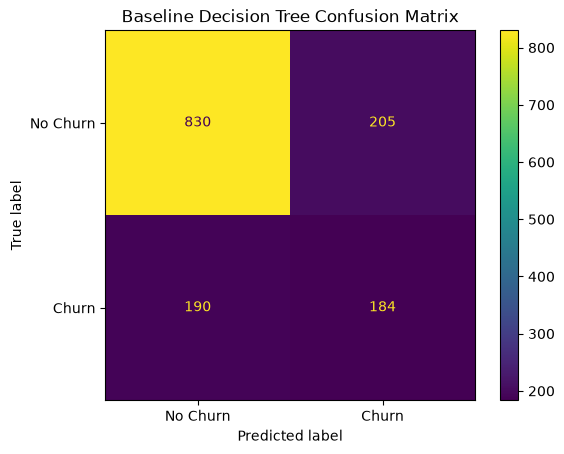

Actual churners correctly caught: 184
Actual churners missed: 190


In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, test_pred)

print("Confusion matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

display.plot()
plt.title("Baseline Decision Tree Confusion Matrix")
plt.show()

correct_churners = cm[1, 1]
missed_churners = cm[1, 0]

print("Actual churners correctly caught:", correct_churners)
print("Actual churners missed:", missed_churners)

The confusion matrix shows correct and incorrect predictions for both classes. Correctly identifying actual churners is especially important because these customers are the ones the company may want to retain.

### Task 12

Because the target classes are imbalanced, accuracy alone should not be trusted. Recall is important because it shows how many actual churners were correctly identified, while F1-score gives a balance between precision and recall.

## Part 6, Overfitting Investigation
### Task 13

In [14]:
train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)
accuracy_gap = train_accuracy - test_accuracy

print("Training accuracy:", train_accuracy)
print("Test accuracy:", test_accuracy)
print("Accuracy gap:", accuracy_gap)

Training accuracy: 0.9980475683351083
Test accuracy: 0.7196593328601846
Accuracy gap: 0.27838823547492375


If training accuracy is much higher than test accuracy, the baseline tree is likely overfitting. This means it has learned the training data very closely but does not generalize equally well to unseen data.

### Task 14

In [15]:
depths = [2, 3, 4, 5, 6, 8, 10, None]

depth_results = []

for depth in depths:
    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    tree.fit(X_train, y_train)

    train_score = accuracy_score(
        y_train,
        tree.predict(X_train)
    )

    test_score = accuracy_score(
        y_test,
        tree.predict(X_test)
    )

    depth_results.append([
        depth,
        train_score,
        test_score,
        train_score - test_score
    ])

depth_results = pd.DataFrame(
    depth_results,
    columns=[
        "max_depth",
        "train_accuracy",
        "test_accuracy",
        "accuracy_gap"
    ]
)

print(depth_results)

   max_depth  train_accuracy  test_accuracy  accuracy_gap
0        2.0        0.765353       0.750887      0.014466
1        3.0        0.791445       0.782115      0.009330
2        4.0        0.796592       0.792051      0.004541
3        5.0        0.803869       0.798439      0.005431
4        6.0        0.810437       0.791341      0.019095
5        8.0        0.837238       0.774308      0.062930
6       10.0        0.878417       0.757275      0.121142
7        NaN        0.998048       0.719659      0.278388


The table compares training and test accuracy at different tree depths. A growing training score with a worsening test score or larger gap indicates increasing overfitting.

### Task 15

TypeError: 'value' must be an instance of str or bytes, not a float

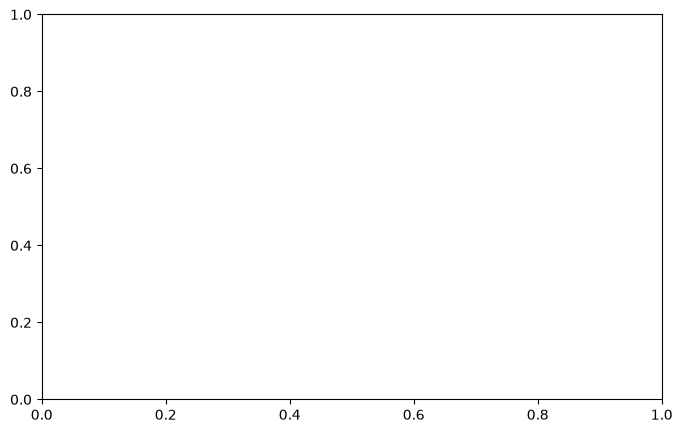

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    depth_results["max_depth"].astype(str),
    depth_results["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depth_results["max_depth"].astype(str),
    depth_results["test_accuracy"],
    marker="o",
    label="Test Accuracy"
)

plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.title("Training vs Test Accuracy by Tree Depth")
plt.legend()
plt.show()

The depth where training accuracy continues to improve while test accuracy stops improving or starts falling is where overfitting becomes more visible. The table and chart provide the evidence for this choice.

## Part 7, Model Selection, Feature Importance & Interpretation
### Task 16

In [17]:
limited_depth_results = depth_results[
    depth_results["max_depth"].notna()
].copy()

limited_depth_results["selection_score"] = (
    limited_depth_results["test_accuracy"]
    - 0.20 * limited_depth_results["accuracy_gap"].abs()
)

best_row = limited_depth_results.sort_values(
    ["selection_score", "test_accuracy"],
    ascending=False
).iloc[0]

best_depth = int(best_row["max_depth"])

print("Selected max_depth:", best_depth)
print("Test accuracy:", best_row["test_accuracy"])
print("Accuracy gap:", best_row["accuracy_gap"])

Selected max_depth: 5
Test accuracy: 0.7984386089425124
Accuracy gap: 0.005430755629727613


The selected depth uses test performance while also considering the training-test gap. This avoids choosing a model only because it fits the training data very well.

### Task 17

In [18]:
best_model = DecisionTreeClassifier(
    max_depth=best_depth,
    random_state=42
)

best_model.fit(X_train, y_train)

best_pred = best_model.predict(X_test)

best_accuracy = accuracy_score(y_test, best_pred)
best_precision = precision_score(y_test, best_pred, zero_division=0)
best_recall = recall_score(y_test, best_pred, zero_division=0)
best_f1 = f1_score(y_test, best_pred, zero_division=0)

best_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [
        best_accuracy,
        best_precision,
        best_recall,
        best_f1
    ]
})

print(best_results)

      Metric     Score
0   Accuracy  0.798439
1  Precision  0.634731
2     Recall  0.566845
3   F1-score  0.598870


This model is simpler than the unrestricted baseline and gives a better balance between fitting the training data and performing on unseen data.

### Task 18

In [19]:
entropy_model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=best_depth,
    random_state=42
)

entropy_model.fit(X_train, y_train)

entropy_pred = entropy_model.predict(X_test)

entropy_accuracy = accuracy_score(y_test, entropy_pred)
entropy_precision = precision_score(y_test, entropy_pred, zero_division=0)
entropy_recall = recall_score(y_test, entropy_pred, zero_division=0)
entropy_f1 = f1_score(y_test, entropy_pred, zero_division=0)

entropy_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [
        entropy_accuracy,
        entropy_precision,
        entropy_recall,
        entropy_f1
    ]
})

print(entropy_results)

      Metric     Score
0   Accuracy  0.797019
1  Precision  0.630952
2     Recall  0.566845
3   F1-score  0.597183


In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline Gini",
        "Selected Gini",
        "Selected Entropy"
    ],
    "Accuracy": [
        baseline_accuracy,
        best_accuracy,
        entropy_accuracy
    ],
    "Precision": [
        baseline_precision,
        best_precision,
        entropy_precision
    ],
    "Recall": [
        baseline_recall,
        best_recall,
        entropy_recall
    ],
    "F1-score": [
        baseline_f1,
        best_f1,
        entropy_f1
    ]
})

print(comparison)

The comparison shows how limiting tree depth changes performance and how entropy compares with the default Gini criterion. Recall and F1-score should also be considered because the churn classes are imbalanced.

### Task 19, Feature Importance

Top 5 features:
Contract_Month-to-month        0.513973
InternetService_Fiber optic    0.163262
tenure                         0.156717
TotalCharges                   0.036499
MonthlyCharges                 0.035922
dtype: float64


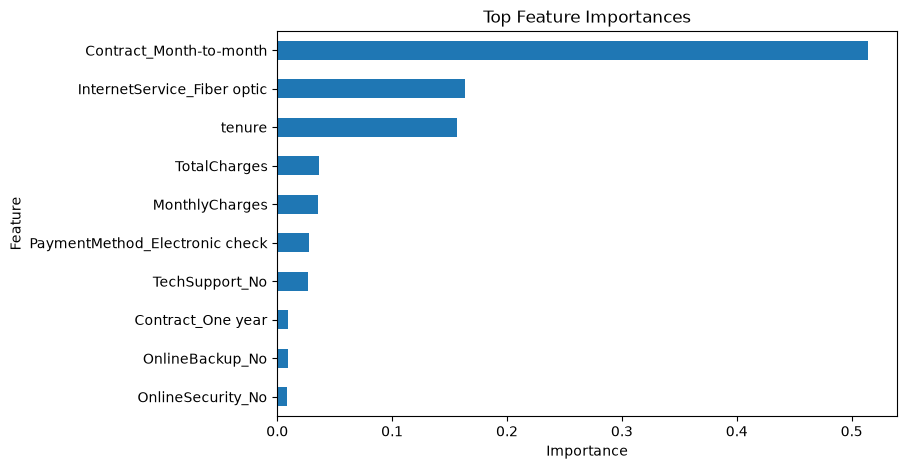

In [20]:
feature_importance = pd.Series(
    best_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Top 5 features:")
print(feature_importance.head(5))

plt.figure(figsize=(8, 5))

feature_importance.head(10).sort_values().plot(
    kind="barh"
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top Feature Importances")
plt.show()

The features at the top of the list have the largest importance values in the selected Decision Tree and contribute more to the tree's splitting decisions.

### Task 20

In [21]:
print("Top features:", feature_importance.head(5).index.tolist())

Top features: ['Contract_Month-to-month', 'InternetService_Fiber optic', 'tenure', 'TotalCharges', 'MonthlyCharges']


The top features can be compared with the patterns found during Lab 2 EDA. If contract type, tenure, charges, or service-related variables appear near the top, this supports relationships observed during the earlier analysis.

## Part 8, Conclusion & Next Steps
### Task 21

The Decision Tree classifier was trained to predict customer churn using the cleaned Telco Customer Churn dataset. The unrestricted baseline tree was compared with trees having different maximum depths to investigate overfitting. A limited-depth tree was selected using test performance and the training-test gap instead of training accuracy alone. Accuracy, precision, recall, F1-score, and a confusion matrix were used to evaluate the models. The main limitation is that a single Decision Tree can still be sensitive to the selected depth and the training data.

### Task 22

If more time were available, I would try another classification algorithm and compare its results with the Decision Tree. I would also investigate useful feature engineering and methods for handling class imbalance. These steps could improve the model's ability to identify customers who are likely to churn.

## Task 23, ID3 From Scratch, Play Badminton Dataset

For this task, no built-in Decision Tree classifier is used. Entropy and information gain are calculated manually.

In [22]:
play_data = {
    "Outlook": [
        "Sunny", "Sunny", "Overcast", "Rain",
        "Rain", "Rain", "Overcast", "Sunny",
        "Sunny", "Rain", "Sunny", "Overcast",
        "Overcast", "Rain"
    ],
    "Temperature": [
        "Hot", "Hot", "Hot", "Mild",
        "Cool", "Cool", "Cool", "Mild",
        "Cool", "Mild", "Mild", "Mild",
        "Hot", "Mild"
    ],
    "Humidity": [
        "High", "High", "High", "High",
        "Normal", "Normal", "Normal", "High",
        "Normal", "Normal", "Normal", "High",
        "Normal", "High"
    ],
    "Wind": [
        "Weak", "Strong", "Weak", "Weak",
        "Weak", "Strong", "Strong", "Weak",
        "Weak", "Weak", "Strong", "Strong",
        "Weak", "Strong"
    ],
    "Play": [
        "No", "No", "Yes", "Yes",
        "Yes", "No", "Yes", "No",
        "Yes", "Yes", "Yes", "Yes",
        "Yes", "No"
    ]
}

play_df = pd.DataFrame(play_data)

print(play_df)

     Outlook Temperature Humidity    Wind Play
0      Sunny         Hot     High    Weak   No
1      Sunny         Hot     High  Strong   No
2   Overcast         Hot     High    Weak  Yes
3       Rain        Mild     High    Weak  Yes
4       Rain        Cool   Normal    Weak  Yes
5       Rain        Cool   Normal  Strong   No
6   Overcast        Cool   Normal  Strong  Yes
7      Sunny        Mild     High    Weak   No
8      Sunny        Cool   Normal    Weak  Yes
9       Rain        Mild   Normal    Weak  Yes
10     Sunny        Mild   Normal  Strong  Yes
11  Overcast        Mild     High  Strong  Yes
12  Overcast         Hot   Normal    Weak  Yes
13      Rain        Mild     High  Strong   No


In [23]:
import math

def entropy(values):
    total = len(values)

    yes_count = 0
    no_count = 0

    for value in values:
        if value == "Yes":
            yes_count += 1
        else:
            no_count += 1

    result = 0

    if yes_count > 0:
        probability = yes_count / total
        result -= probability * math.log2(probability)

    if no_count > 0:
        probability = no_count / total
        result -= probability * math.log2(probability)

    return result

In [24]:
def information_gain(data, attribute):
    total_entropy = entropy(data["Play"])

    values = data[attribute].unique()

    weighted_entropy = 0

    for value in values:
        part = data[data[attribute] == value]
        weight = len(part) / len(data)
        weighted_entropy += weight * entropy(part["Play"])

    return total_entropy - weighted_entropy

In [25]:
attributes = [
    "Outlook",
    "Temperature",
    "Humidity",
    "Wind"
]

print("Information Gain at root:")

for attribute in attributes:
    gain = information_gain(play_df, attribute)
    print(attribute, "=", round(gain, 4))

Information Gain at root:
Outlook = 0.2467
Temperature = 0.0292
Humidity = 0.1518
Wind = 0.0481


In [26]:
def majority_class(data):
    counts = data["Play"].value_counts()

    if counts.get("Yes", 0) >= counts.get("No", 0):
        return "Yes"

    return "No"


def id3(data, attributes):
    if len(data["Play"].unique()) == 1:
        return data["Play"].iloc[0]

    if len(attributes) == 0:
        return majority_class(data)

    best_attribute = attributes[0]
    best_gain = information_gain(data, best_attribute)

    for attribute in attributes:
        gain = information_gain(data, attribute)

        print(
            "Attribute:",
            attribute,
            "Gain:",
            round(gain, 4)
        )

        if gain > best_gain:
            best_gain = gain
            best_attribute = attribute

    print("Best attribute:", best_attribute)
    print()

    tree = {best_attribute: {}}

    remaining_attributes = []

    for attribute in attributes:
        if attribute != best_attribute:
            remaining_attributes.append(attribute)

    values = data[best_attribute].unique()

    for value in values:
        part = data[data[best_attribute] == value]

        print(
            "Split:",
            best_attribute,
            "=",
            value
        )

        tree[best_attribute][value] = id3(
            part,
            remaining_attributes
        )

    return tree

In [27]:
attributes = [
    "Outlook",
    "Temperature",
    "Humidity",
    "Wind"
]

print("ID3 training:")
tree = id3(play_df, attributes)

print("\nFinal ID3 Tree:")
print(tree)

ID3 training:
Attribute: Outlook Gain: 0.2467
Attribute: Temperature Gain: 0.0292
Attribute: Humidity Gain: 0.1518
Attribute: Wind Gain: 0.0481
Best attribute: Outlook

Split: Outlook = Sunny
Attribute: Temperature Gain: 0.571
Attribute: Humidity Gain: 0.971
Attribute: Wind Gain: 0.02
Best attribute: Humidity

Split: Humidity = High
Split: Humidity = Normal
Split: Outlook = Overcast
Split: Outlook = Rain
Attribute: Temperature Gain: 0.02
Attribute: Humidity Gain: 0.02
Attribute: Wind Gain: 0.971
Best attribute: Wind

Split: Wind = Weak
Split: Wind = Strong

Final ID3 Tree:
{'Outlook': {'Sunny': {'Humidity': {'High': 'No', 'Normal': 'Yes'}}, 'Overcast': 'Yes', 'Rain': {'Wind': {'Weak': 'Yes', 'Strong': 'No'}}}}


The ID3 implementation calculates entropy and information gain directly and chooses the attribute with the highest information gain at each split. No built-in Decision Tree classifier is used for this task.

## Submission Checklist

- [x] Student-info block
- [x] Problem Definition
- [x] Dataset Verification
- [x] Feature/Target Preparation
- [x] Train/Test Split
- [x] Baseline Decision Tree
- [x] Model Evaluation
- [x] Overfitting Experiment
- [x] Model Comparison
- [x] Feature Importance
- [x] Interpretation
- [x] Conclusion
- [x] Next Steps
- [x] ID3 from Scratch
- [x] Written interpretation for tables, plots, and metrics